# Prediksi Biaya Asuransi Kesehatan Menggunakan Algoritma XGBoost dan *Ensemble Learning* — Projek Machine Learning Ketiga
Notebook ini bertujuan memprediksi **charges** seorang pasien rumah sakit berdasarkan usia, jenis kelamin, bmi, jumlah anak, status perokok, dan daerah. Ini adalah proyek machine learning ketiga saya, dengan fokus melatih skill: menganalisis hubungan antar fitur lewat EDA dan membandingkan performa model berdasarkan nilai MAE dan R².



In [34]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import KFold, cross_validate
from sklearn.ensemble import VotingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score

## EDA
Data dimuat dan dicek strukturnya. Dalam dataset ini, tidak ada satupun kolom yang memiliki nilai kosong, kemudian saya kelompokkan data menjadi dua kelompok: data numerik dan data kategori. Selanjutnya saya menetapkan kolom **charges** sebagai target.

In [2]:
my_data = pd.read_csv('insurance.csv')
# my_data.head()
print(my_data.shape)
print(my_data.dtypes)
print(my_data.describe())
print(my_data.info())
# print(my_data.isnull().sum())

num_col = my_data.select_dtypes(include = 'number').columns.tolist()
cat_col = my_data.select_dtypes(exclude = 'number').columns.tolist()
print(num_col)
print(cat_col)



(1338, 7)
age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object
               age          bmi     children       charges
count  1338.000000  1338.000000  1338.000000   1338.000000
mean     39.207025    30.663397     1.094918  13270.422265
std      14.049960     6.098187     1.205493  12110.011237
min      18.000000    15.960000     0.000000   1121.873900
25%      27.000000    26.296250     0.000000   4740.287150
50%      39.000000    30.400000     1.000000   9382.033000
75%      51.000000    34.693750     2.000000  16639.912515
max      64.000000    53.130000     5.000000  63770.428010
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3  

### Distribusi Target (charges)

Axes(0.125,0.11;0.775x0.77)
1.5158796580240388


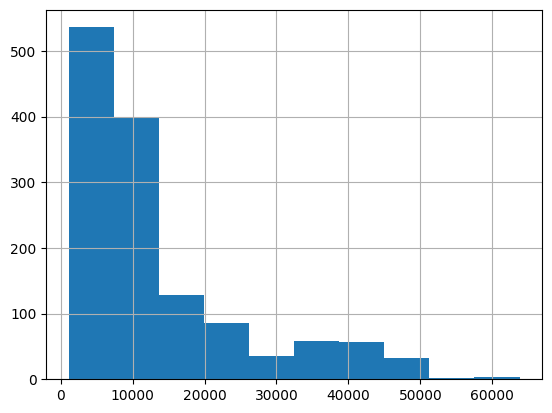

In [3]:
print(my_data['charges'].hist())
print(my_data['charges'].skew())
# print(my_data['region'].value_counts(normalize=True))
# print(my_data['sex'].value_counts(normalize=True))

Histogram terlihat skewed ke kanan akibat outlier, namun hal ini normal dalam konteks asuransi. Karena model yang saya gunakan berbasis tree dan boost, maka kondisi skewed tidak memengaruhi cara model mempelajari data dan memprediksi nilai.

### Scatter plot: Fitur numerik vs charges

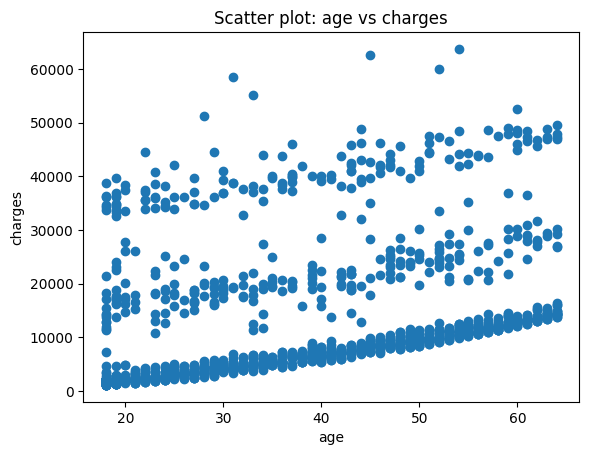

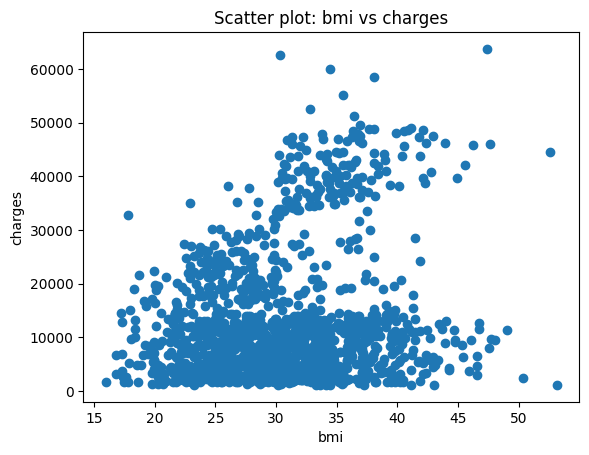

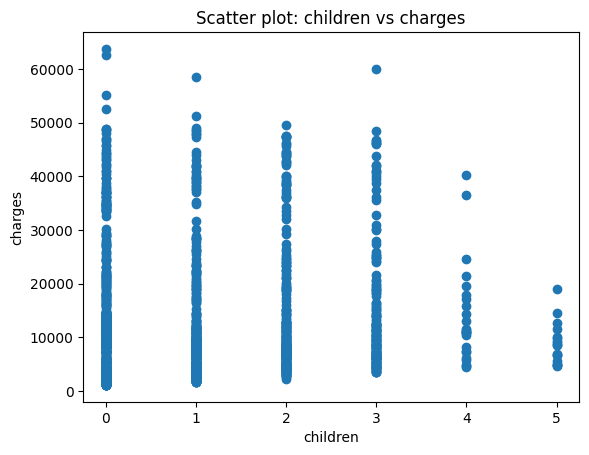

In [4]:
num_col = [col for col in num_col if col != 'charges']
for col in num_col:
  plt.figure()
  plt.scatter(my_data[col], my_data['charges'])
  plt.title(f'Scatter plot: {col} vs charges')
  plt.xlabel(col)
  plt.ylabel('charges')
  plt.show()

1. Terdapat korelasi positif antara **age** dengan **charges**. Namun yang jadi perhatian adalah adanya lapisan yang terbentuk. Hal tersebut mungkin disebabkan oleh kelompok perokok yang memengaruhi biaya asuransi pada usia tertentu (selanjutnya pernyataan tersebut akan dibuktikan melalui scatter plot).
2. Terdapat korelasi positif antara **bmi** dengan **charges**. Dalam grafik terdapat dua grup yang terbentuk (atas dan bawah). Selain itu, terdapat temuan menarik, jika seseorang memiliki skor BMI sangat tinggi biasanya dia memiliki tagihan asuransi yang tinggi juga. Namun terdapat beberapa orang dengan skor BMI yang sangat tinggi memiliki biaya asuransi yang rendah. Dalam hal ini, saya memiliki asumsi yang sama seperti pada poin pertama dimana kelompok perokok memiliki pengaruh dalam korelasi ini.
3. Berdasarkan grafik tersebut, dapat disimpulkan bahwa variabel children bersifat diskrit dan membentuk kolom vertikal, di mana sebaran biaya asuransi pada setiap kategori jumlah anak sangat luas tanpa menunjukkan korelasi linier yang kuat.

#### Pengaruh Age dan Smoker terhadap Charges (Pembuktian asumsi poin 1)

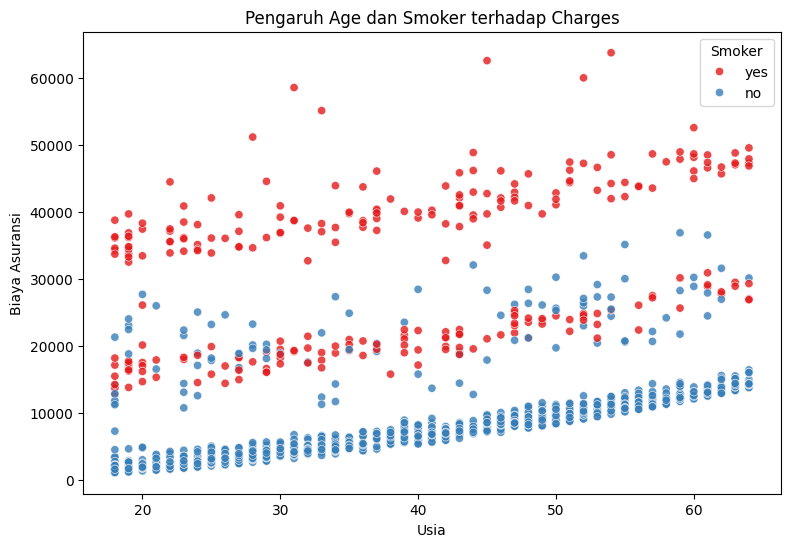

In [5]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=my_data, x='age', y='charges', hue='smoker', palette='Set1', alpha=0.8)
plt.title('Pengaruh Age dan Smoker terhadap Charges')
plt.xlabel('Usia')
plt.ylabel('Biaya Asuransi')
plt.legend(title='Smoker')
plt.show()

#### Pengaruh BMI dan Smoker trehadap Charges (pembuktian asumsi poin 2)

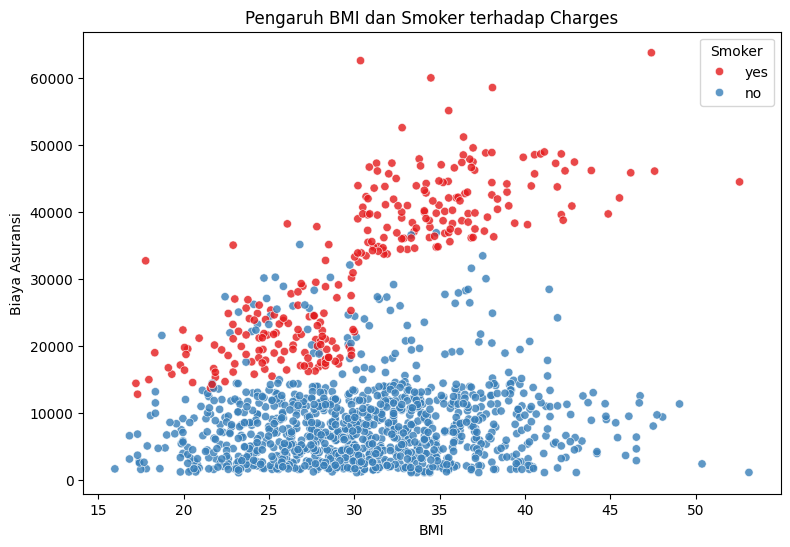

In [6]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=my_data, x='bmi', y='charges', hue='smoker', palette='Set1', alpha=0.8)
plt.title('Pengaruh BMI dan Smoker terhadap Charges')
plt.xlabel('BMI')
plt.ylabel('Biaya Asuransi')
plt.legend(title='Smoker')
plt.show()

### Boxplot: Fitur kategori vs charges

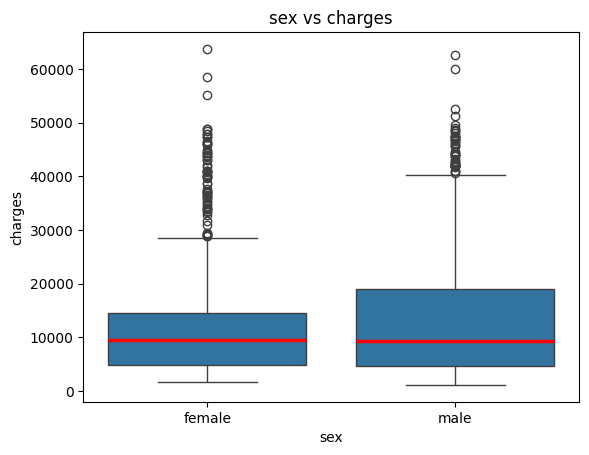

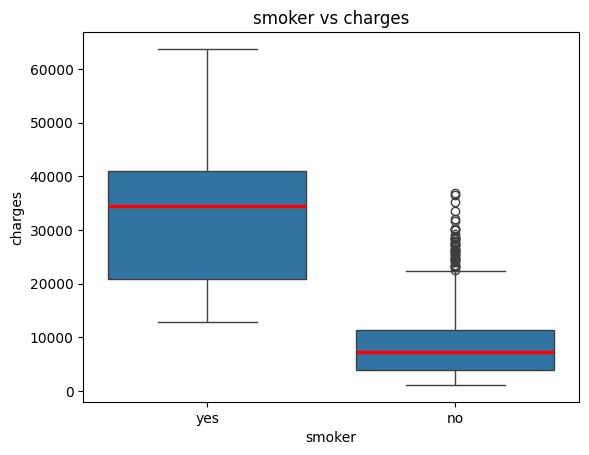

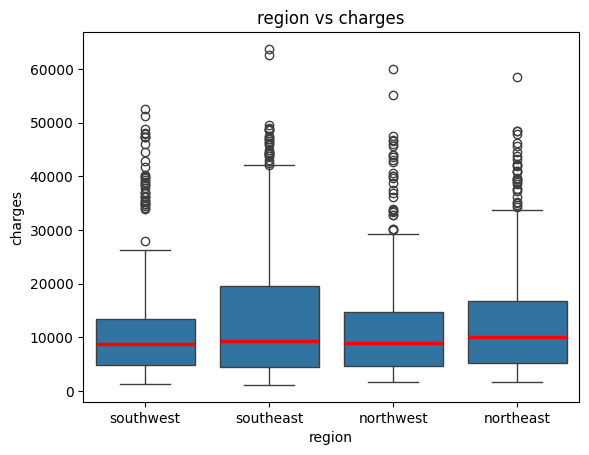

In [7]:
for col in cat_col:
  sns.boxplot(x=col, y='charges', data=my_data, medianprops=dict(color='red', linewidth=2.5))
  plt.title(f"{col} vs charges")
  plt.show()

### Matriks korelasi antar variabel numerik
Matriks korelasi bertujuan untuk mengetahui apakah terdapat dua fitur yang saling berkorelasi kuat. Fitur yang saling berkorelasi kuat akan dipertimbangkan untuk didrop atau tetap digunakan.

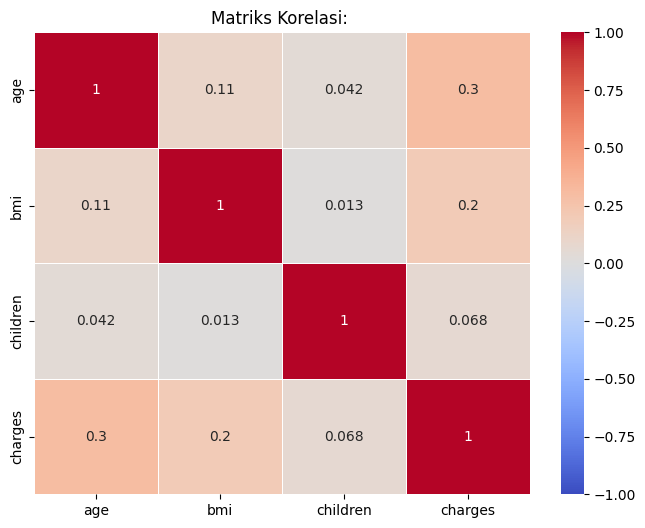

In [8]:
plt.figure(figsize=(8, 6))
sns.heatmap(my_data.corr(numeric_only=True),annot=True,cmap='coolwarm',linewidths=0.5,vmin=-1, vmax=1)
plt.title('Matriks Korelasi: ')
plt.show()

Berdasarkan matriks korelasi, tidak ditemukan fitur yang memiliki korelasi kuat satu sama lain, sehingga seluruh fitur diputuskan untuk tetap dipertahankan dalam model tanpa perlu dilakukan penghapusan (drop).

## Feature Engineering & Preprocessing

### Manual Binary Encoding
**sex** dan **smoker** tidak memiliki urutan logis, sehingga dilakukan binary encoding secara manual.

In [9]:
sexmap = {'female':0,'male':1}
smokermap = {'no':0,'yes':1}

my_data['sex'] = my_data['sex'].map(sexmap)
my_data['smoker'] = my_data['smoker'].map(smokermap)

print(my_data.head())

   age  sex     bmi  children  smoker     region      charges
0   19    0  27.900         0       1  southwest  16884.92400
1   18    1  33.770         1       0  southeast   1725.55230
2   28    1  33.000         3       0  southeast   4449.46200
3   33    1  22.705         0       0  northwest  21984.47061
4   32    1  28.880         0       0  northwest   3866.85520


### Pemilihan Fitur dan Target
fitur: **age, sex, bmi, children, smoker, region**

target: **charges**

In [10]:
X = my_data.drop(columns = ['charges'])
y = my_data['charges']

### Split Data & One-Hot Encoding
Data displit terlebih dahulu (80% latih, 20% uji, `random_state=42`) sebelum encoding **region** (kategori tanpa urutan) menggunakan `OneHotEncoder`. Encoder di-*fit* hanya pada `X_train`, lalu di-*transform* ke `X_test`, untuk menghindari data leakage.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

OH_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

OH_cols_train = pd.DataFrame(OH_encoder.fit_transform(X_train[['region']]),columns=OH_encoder.get_feature_names_out(['region']), index=X_train.index)
OH_cols_test = pd.DataFrame(OH_encoder.transform(X_test[['region']]),columns=OH_encoder.get_feature_names_out(['region']),index=X_test.index)

num_X_train = X_train.drop(['region'], axis=1)
num_X_test = X_test.drop(['region'], axis=1)

X_train_final = pd.concat([num_X_train, OH_cols_train], axis=1)
X_test_final = pd.concat([num_X_test, OH_cols_test], axis=1)

## Training Model

Enam pendekatan dibandingkan secara bertahap: (1-2) Random Forest sebagai baseline, (3-4) XGBoost tanpa dan dengan tuning hyperparameter, serta (5-6) ensembling. Semua model dilatih pada `X_train_final` dan dievaluasi pada `X_test_final` yang sama dengan tiga metrik:

- **MAE**: rata-rata selisih absolut antara prediksi dan nilai sebenarnya, dalam satuan `charges`.
- **MAE relatif**: MAE dibagi rata-rata `charges` pada data uji, agar mudah dibandingkan.
- **R²**: proporsi variasi `charges` yang berhasil dijelaskan model (semakin mendekati 1 semakin baik).

Setelah itu dilakukan cross validation untuk memilih model akhir, feature importance untuk melihat fitur yang paling berpengaruh, dan evaluasi per kelompok perokok.

> Catatan: satu eksperimen tambahan, fitur interaksi `smoker × bmi` pada XGBoost, tidak memperbaiki hasil (MAE 2.474,46; R² 0,8716 vs 2.455,41 dan 0,8749 pada Model 4) dan dihapus dari notebook. Model berbasis pohon tampaknya sudah menangkap interaksi itu sendiri.

#### Model 1: RandomForestRegressor

Random Forest membangun banyak pohon keputusan secara independen pada sampel data yang berbeda, lalu merata-ratakan prediksinya. Model ini dijalankan dengan parameter bawaan (100 pohon, `random_state=0`) sebagai **baseline**, yaitu titik acuan untuk menilai apakah model-model berikutnya benar-benar lebih baik.

In [12]:
model = RandomForestRegressor(random_state=0)
model.fit(X_train_final, y_train)

RandomForestRegressor(random_state=0)

In [13]:
pred = model.predict(X_test_final)
mae = mean_absolute_error(y_test,pred)
print(mae)

mae_percentage = (mae / y_test.mean()) * 100
print(f"MAE relatif: {mae_percentage:.2f}%")

r2 = r2_score(y_test, pred)
print(f"Nilai R2 : {r2}")

2513.814175925312
MAE relatif: 19.38%
Nilai R2 : 0.8614100827216837


#### Model 2: RandomForestRegressor dengan parameter tambahan

Jumlah pohon dinaikkan menjadi 300 (`n_estimators=300`) untuk menguji apakah lebih banyak pohon memperbaiki prediksi. Catatan: `random_state` juga berubah dari 0 menjadi 42, sehingga selisih kecil terhadap Model 1 bisa sebagian berasal dari perbedaan seed, bukan hanya jumlah pohon.

In [14]:
model2 = RandomForestRegressor(n_estimators=300, random_state=42)
model2.fit(X_train_final, y_train)

RandomForestRegressor(n_estimators=300, random_state=42)

In [15]:
pred2 = model2.predict(X_test_final)
mae = mean_absolute_error(y_test,pred2)
print(mae)

mae_percentage = (mae / y_test.mean()) * 100
print(f"MAE relatif: {mae_percentage:.2f}%")

r2 = r2_score(y_test, pred2)
print(f"Nilai R2 : {r2}")

2523.8392444669494
MAE relatif: 19.46%
Nilai R2 : 0.8636617873119237


#### Model 3: XGBoostRegressor

XGBoost adalah *gradient boosting*: pohon dibangun **berurutan**, dan setiap pohon baru berusaha memperbaiki kesalahan gabungan pohon-pohon sebelumnya (berbeda dari Random Forest yang pohonnya independen). Model ini dijalankan dengan parameter bawaan untuk melihat performa XGBoost "apa adanya" sebelum di-tuning.

In [16]:
model3 = XGBRegressor(random_state=42)
model3.fit(X_train_final, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=None,
             n_jobs=None, num_parallel_tree=None, ...)

In [17]:
pred3 = model3.predict(X_test_final)
mae = mean_absolute_error(y_test,pred3)
print(mae)

mae_percentage = (mae / y_test.mean()) * 100
print(f"MAE relatif: {mae_percentage:.2f}%")

r2 = r2_score(y_test, pred3)
print(f"Nilai R2 : {r2}")

2853.57776278772
MAE relatif: 22.00%
Nilai R2 : 0.8443469433132654


#### Model 4: XGBoostRegressor dengan hypermarameter tuning

Parameter diubah menjadi `n_estimators=300`, `learning_rate=0.05`, dan `max_depth=4`: pohon dibuat lebih dangkal dan setiap pohon hanya berkontribusi kecil, dengan jumlah pohon yang lebih banyak sebagai gantinya. Kombinasi ini umumnya mengurangi risiko overfitting pada dataset kecil (di sini sekitar 1.070 baris latih).

In [18]:
model4 = XGBRegressor(n_estimators=300,learning_rate=0.05,max_depth=4,random_state=42)
model4.fit(X_train_final, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=300,
             n_jobs=None, num_parallel_tree=None, ...)

In [19]:
pred4 = model4.predict(X_test_final)
mae = mean_absolute_error(y_test,pred4)
print(mae)

mae_percentage = (mae / y_test.mean()) * 100
print(f"MAE relatif: {mae_percentage:.2f}%")

r2 = r2_score(y_test, pred4)
print(f"Nilai R2 : {r2}")

2455.4077317094066
MAE relatif: 18.93%
Nilai R2 : 0.8749375025471773


#### Model 5: Ensembling menggunakan Model 1 dan Model 4

Ensembling menggabungkan prediksi beberapa model. Di sini prediksi Random Forest (Model 1) dan XGBoost hasil tuning (Model 4) dirata-ratakan dengan bobot sama: `(pred + pred4) / 2`. Idenya, kesalahan kedua model tidak sepenuhnya sama sehingga rata-ratanya bisa lebih stabil. Catatan: MAE absolut tidak dicetak pada sel ini (hanya MAE relatif dan R²).

In [20]:
pred_ensemble = (pred + pred4) / 2
r2_ensemble = r2_score(y_test, pred_ensemble)

mae_ensemble = mean_absolute_error(y_test, pred_ensemble)

relative_mae_ensemble = (mae_ensemble / np.mean(y_test)) * 100

print(f"Hasil Ensembling (Random Forest + XGBoost):")
print(f"Nilai R2        : {r2_ensemble}")
print(f"Relative MAE    : {relative_mae_ensemble:.2f}%")

Hasil Ensembling (Random Forest + XGBoost):
Nilai R2        : 0.8735190356867187
Relative MAE    : 18.89%


#### Model 6: Pengaturan bobot dari kedua model

Variasi dari Model 5 dengan bobot tidak sama: 20% Random Forest dan 80% XGBoost hasil tuning (`0.2 * pred + 0.8 * pred4`). Bobot yang lebih besar diberikan pada XGBoost karena skornya lebih baik daripada Random Forest pada Model 1. Bobot ini diatur manual dan dievaluasi pada `X_test` yang sama, sehingga skornya sedikit optimistis.

In [21]:
pred_ensemble_weighted = (0.2 * pred) + (0.8 * pred4)

from sklearn.metrics import r2_score, mean_absolute_error
import numpy as np

print(f"R2 (Weighted): {r2_score(y_test, pred_ensemble_weighted)}")
print(f"Relative MAE (Weighted): {(mean_absolute_error(y_test, pred_ensemble_weighted) / np.mean(y_test)) * 100:.2f}%")

R2 (Weighted): 0.8756529727647898
Relative MAE (Weighted): 18.85%


## Perbandingan Seluruh Model

| No | Model | MAE | MAE relatif | R² |
|---|---|---|---|---|
| 1 | Random Forest (parameter bawaan) | 2.513,81 | 19,38% | 0,8614 |
| 2 | Random Forest (300 pohon) | 2.523,84 | 19,46% | 0,8637 |
| 3 | XGBoost (parameter bawaan) | 2.853,58 | 22,00% | 0,8443 |
| 4 | XGBoost (hyperparameter tuning) | 2.455,41 | 18,93% | 0,8749 |
| 5 | Ensemble RF + XGBoost (bobot 50:50) | – | 18,89% | 0,8735 |
| 6 | Ensemble RF + XGBoost (bobot 20:80) | – | **18,85%** | **0,8757** |

MAE absolut Model 6 dan 7 tidak dicetak pada notebook (hanya MAE relatif dan R²). Angka tebal menandai nilai terbaik pada kolom masing-masing. Selanjutnya akan dilakukan Cross Validation untuk mencari model mana yang benar-benar bagus.

## Cross Validation

Hasil pada satu data uji bisa dipengaruhi cara data kebetulan terbagi. Karena itu dilakukan 10-fold cross validation **pada data latih** untuk membandingkan dua kandidat dengan R² tertinggi: Model 4 (XGBoost hasil tuning) dan Model 6 (ensemble 20:80, dibuat dengan `VotingRegressor`). Skor CV dan skor data uji adalah dua pengukuran berbeda, sehingga tidak dibandingkan langsung.

In [22]:
from sklearn.ensemble import VotingRegressor

scoring_metrics = {
    'MAE': 'neg_mean_absolute_error',
    'R2': 'r2'
}

cv_m4 = cross_validate(model4, X_train_final, y_train, cv=10, scoring=scoring_metrics)

print("=== MODEL 4 (XGBoost) ===")
print(f"R2 Rata-rata  : {cv_m4['test_R2'].mean():.4f}")
print(f"MAE Rata-rata : {-cv_m4['test_MAE'].mean():.4f}\n")

ensemble_model = VotingRegressor(
    estimators=[('rf', model), ('xgb', model4)],
    weights=[0.2, 0.8]
)

cv_m7 = cross_validate(ensemble_model, X_train_final, y_train, cv=10, scoring=scoring_metrics)

print("=== MODEL 7 (Ensemble 20:80) ===")
print(f"R2 Rata-rata  : {cv_m7['test_R2'].mean():.4f}")
print(f"MAE Rata-rata : {-cv_m7['test_MAE'].mean():.4f}")

=== MODEL 4 (XGBoost) ===
R2 Rata-rata  : 0.8265
MAE Rata-rata : 2802.8761

=== MODEL 7 (Ensemble 20:80) ===
R2 Rata-rata  : 0.8302
MAE Rata-rata : 2782.0377


**Hasil:** Model 6 (ensemble 20:80) sedikit lebih baik daripada Model 4 pada rata-rata CV: R² 0,8302 vs 0,8265 dan MAE 2.782,04 vs 2.802,88. Arahnya sama dengan hasil pada data uji, sehingga Model 6 dipilih sebagai model akhir. Namun selisihnya sangat kecil (R² 0,0037; MAE sekitar 21), dan standar deviasi antar-fold belum dicetak. Jika selisih itu lebih kecil daripada standar deviasinya, kedua model sebaiknya dianggap setara.

## Feature Importances

Ensemble tidak punya `feature_importances_` sendiri, sehingga importance Model 6 dihitung sebagai rata-rata berbobot yang sama dengan bobot model: `0,2 × Random Forest + 0,8 × XGBoost`.

/tmp/ipykernel_2091/510537543.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='viridis')


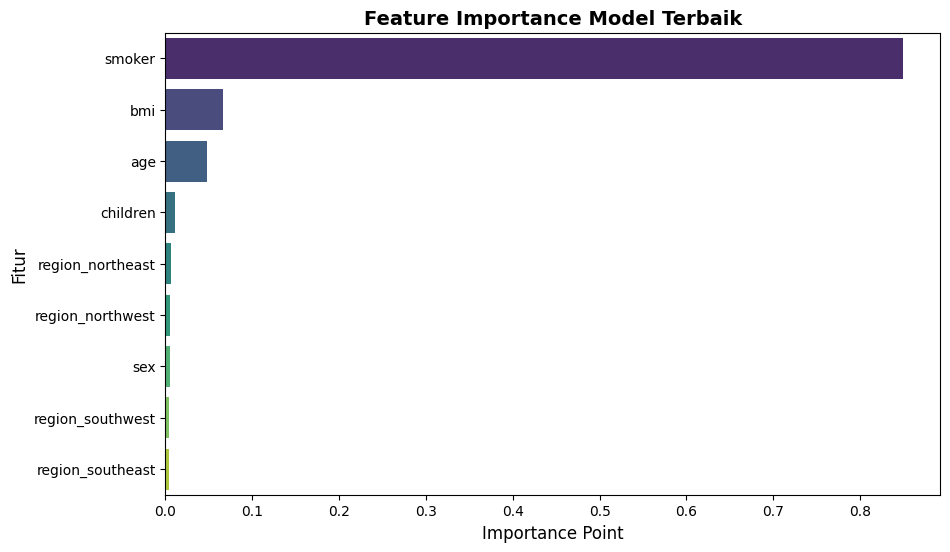

In [23]:
importances_rf = model.feature_importances_
importances_xgb = model4.feature_importances_

combined_importance = (0.2*importances_rf)+(0.8*importances_xgb)

feature_importance_df = pd.DataFrame({'Feature': X_train_final.columns,'Importance': combined_importance}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='viridis')
plt.title('Feature Importance Model Terbaik', fontsize=14, fontweight='bold')
plt.xlabel('Importance Point', fontsize=12)
plt.ylabel('Fitur', fontsize=12)
plt.show()

In [37]:
result_xgb = permutation_importance(model4,X_test_final,y_test,n_repeats=10, random_state=42,scoring='r2')

sorted_idx = result_xgb.importances_mean.argsort()[::-1]

print("=== PERMUTATION IMPORTANCE (MODEL 4 / XGBOOST) ===")
for idx in sorted_idx:
    print(f"Fitur: {X_test_final.columns[idx]:<16} | Penurunan R²: {result_xgb.importances_mean[idx]:.4f} +/- {result_xgb.importances_std[idx]:.4f}")

=== PERMUTATION IMPORTANCE (MODEL 4 / XGBOOST) ===
Fitur: smoker           | Penurunan R²: 1.4076 +/- 0.1022
Fitur: bmi              | Penurunan R²: 0.2494 +/- 0.0259
Fitur: age              | Penurunan R²: 0.1841 +/- 0.0150
Fitur: children         | Penurunan R²: 0.0179 +/- 0.0035
Fitur: region_northeast | Penurunan R²: 0.0027 +/- 0.0021
Fitur: region_southwest | Penurunan R²: 0.0008 +/- 0.0010
Fitur: region_southeast | Penurunan R²: -0.0002 +/- 0.0008
Fitur: region_northwest | Penurunan R²: -0.0017 +/- 0.0008
Fitur: sex              | Penurunan R²: -0.0018 +/- 0.0015


**Interpretasi:** `smoker` mendominasi dengan importance sekitar 0,85, jauh di atas `bmi` (sekitar 0,07) dan `age` (sekitar 0,05). `children`, `sex`, dan keempat kolom `region` hampir tidak berkontribusi. Ini sesuai temuan EDA bahwa status perokok memisahkan biaya dengan sangat jelas. Menariknya `bmi` sedikit di atas `age`, padahal korelasi linear `age` dengan `charges` lebih tinggi. Hal ini sejalan dengan pola ambang pada perokok (biaya melompat di sekitar BMI 30) yang lebih mudah ditangkap model berbasis pohon daripada korelasi linear. Catatan: importance bawaan model pohon cenderung condong ke fitur numerik, sehingga angkanya paling tepat dibaca sebagai urutan kasar, bukan nilai pasti.

## Split Smoker Group

Dari EDA dan feature importance, status perokok adalah pemisah utama biaya. Bagian ini mengevaluasi prediksi Model 6 pada data uji secara terpisah untuk perokok dan non-perokok, menggunakan prediksi yang sama (model tidak dilatih ulang per kelompok).

### Buat Dataframe Evaluasi

In [24]:
eval_df = X_test_final.copy()
eval_df['actual_cost'] = y_test.values
eval_df['predicted_cost'] = pred_ensemble_weighted

### Split Data

In [25]:
smoker_group = eval_df[eval_df['smoker'] == 1]
non_smoker_group = eval_df[eval_df['smoker'] == 0]

print("Jumlah data perokok: {len(smoker_group)}")
print(f"Jumlah data non-perokok: {len(non_smoker_group)}")

Jumlah data perokok: {len(smoker_group)}
Jumlah data non-perokok: 214


### Hitung MAE Setiap Kelompok

In [26]:
mae_smoker = mean_absolute_error(smoker_group['actual_cost'], smoker_group['predicted_cost'])
r2_smoker = r2_score(smoker_group['actual_cost'], smoker_group['predicted_cost'])

mae_non_smoker = mean_absolute_error(non_smoker_group['actual_cost'], non_smoker_group['predicted_cost'])
r2_non_smoker = r2_score(non_smoker_group['actual_cost'], non_smoker_group['predicted_cost'])

print("=== HASIL ANALISIS KELOMPOK (MODEL 7) ===")
print(f"Kelompok PEROKOK     -> MAE: {mae_smoker:.2f} | R2: {r2_smoker:.4f}")
print(f"Kelompok NON-PEROKOK -> MAE: {mae_non_smoker:.2f} | R2: {r2_non_smoker:.4f}")

=== HASIL ANALISIS KELOMPOK (MODEL 7) ===
Kelompok PEROKOK     -> MAE: 2597.72 | R2: 0.8378
Kelompok NON-PEROKOK -> MAE: 2405.30 | R2: 0.4377


In [28]:
# MAE relatif per kelompok: MAE dibagi rata-rata biaya aktual di kelompok itu
for nama, g in [('Perokok', smoker_group), ('Non-perokok', non_smoker_group)]:
    mae_g = mean_absolute_error(g['actual_cost'], g['predicted_cost'])
    print(f"{nama:12s} n ={len(g):4d} | MAE relatif: {mae_g / g['actual_cost'].mean() * 100:.2f}%")

Perokok      n =  54 | MAE relatif: 7.82%
Non-perokok  n = 214 | MAE relatif: 30.59%


**Interpretasi:** pada non-perokok R² hanya 0,4377 (214 baris), jauh di bawah perokok yang 0,8378 (54 baris), padahal MAE absolutnya mirip (2.405,30 vs 2.597,72). Karena biaya non-perokok jauh lebih kecil (median sekitar 7.500 vs sekitar 34.000 pada EDA), galat yang sama besar berarti persentase kesalahan yang jauh lebih besar pada non-perokok: perkiraan kasar sekitar sepertiga dari nilai tipikalnya, dibanding sekitar 8% pada perokok. Sel kode di atas menghitung angka pastinya. R² yang tinggi secara keseluruhan sebagian besar berasal dari kemampuan model memisahkan perokok dari non-perokok. Variasi di dalam kelompok non-perokok sendiri belum banyak dijelaskan model. Jumlah perokok pada data uji hanya 54 baris, sehingga angka kelompok ini cukup noisy.

## Analisis Hasil

**1. Tuning hyperparameter memberi perbaikan terbesar.** XGBoost bawaan (Model 3) menjadi model terburuk (MAE relatif 22,00%, R² 0,8443), bahkan di bawah Random Forest. Setelah `learning_rate`, `max_depth`, dan `n_estimators` disesuaikan (Model 4), MAE turun dari 2.853,58 menjadi 2.455,41 (sekitar 14%) dan R² naik 0,031 menjadi 0,8749. Kemungkinan parameter bawaan terlalu agresif untuk dataset sekecil ini sehingga cenderung overfitting. Dugaan ini belum diuji, misalnya dengan membandingkan skor data latih dan data uji.

**2. Random Forest sudah jenuh.** Menaikkan pohon dari 100 ke 300 (Model 2) hampir tidak mengubah hasil (R² 0,8614 menjadi 0,8637). Selisih sekecil ini tidak bermakna, apalagi `random_state` ikut berubah.

**3. Ensembling hanya marginal, tetapi konsisten di CV.** Pada data uji, Model 6 (20:80) unggul atas Model 4 hanya 0,0008 pada R² (0,8757 vs 0,8749). Pada 10-fold CV, Model 6 juga sedikit lebih baik (R² 0,8302 vs 0,8265; MAE 2.782,04 vs 2.802,88). Dua pengukuran yang searah menambah keyakinan, tetapi selisihnya tetap kecil dan standar deviasi antar-fold belum dicek. Bobot 20:80 awalnya dipilih berdasarkan data uji, sehingga CV belum sepenuhnya independen terhadap pilihan itu. Model 5 (50:50) berada di antara kedua model dasarnya. Kemungkinan Random Forest dan XGBoost, yang sama-sama berbasis pohon pada fitur yang sama, membuat kesalahan yang mirip.

**4. Status perokok adalah faktor yang mendominasi.** Importance `smoker` sekitar 0,85, jauh di atas `bmi` dan `age`, sedangkan `sex`, `children`, dan `region` hampir tidak berpengaruh. Ini mengonfirmasi dugaan dari EDA.

**5. Model kuat pada perokok, lemah pada non-perokok.** Pada kelompok perokok R² mencapai 0,8378, sedangkan pada non-perokok hanya 0,4377 dengan MAE absolut yang mirip (2.597,72 vs 2.405,30). Karena biaya non-perokok jauh lebih kecil, kesalahan yang sama berarti persentase galat yang jauh lebih besar pada kelompok ini. Skor keseluruhan 87% sebagian besar mencerminkan pemisahan perokok vs non-perokok, bukan akurasi merata di semua pasien. Sisa kesalahan kemungkinan berasal dari faktor yang tidak tercatat di dataset, misalnya riwayat penyakit atau jenis perawatan.

**6. Fitur interaksi `smoker × bmi` tidak membantu.** Eksperimen ini (sudah dihapus dari notebook) memberi MAE 2.474,46 dan R² 0,8716, sedikit di bawah Model 4. Pola ambang BMI pada perokok bisa ditemukan sendiri oleh model berbasis pohon, sehingga fitur buatan itu kemungkinan redundan.

## Kesimpulan

- **Model akhir: ensemble Random Forest + XGBoost dengan bobot 20:80 (Model 6).** Pada data uji, model ini mencapai R² 0,8757 dan MAE relatif 18,85%. Pada 10-fold CV, ia juga sedikit di atas Model 4 (R² 0,8302 vs 0,8265). Selisihnya kecil, sehingga Model 4 (XGBoost tuning, R² 0,8749) praktis setara dan lebih sederhana jika kemudahan lebih diutamakan.
- **Perubahan paling berdampak adalah tuning hyperparameter** (R² naik 0,031 dari Model 3 ke Model 4). Ensembling dan fitur interaksi memberi hasil marginal atau tidak berdampak.
- **Faktor utama biaya asuransi adalah status perokok** (importance sekitar 0,85), diikuti `bmi` dan `age`. `sex`, `children`, dan `region` hampir tidak berpengaruh.
- **Kualitas prediksi tidak merata.** R² pada perokok 0,8378 vs 0,4377 pada non-perokok. Model cukup andal untuk memperkirakan biaya perokok, tetapi prediksi untuk non-perokok jauh kurang pasti dalam persentase.

### Keterbatasan
- Dataset kecil (1.338 baris; 268 baris data uji, 54 di antaranya perokok), sehingga selisih R² di bawah sekitar 0,01 antar-model sebaiknya tidak dianggap bermakna.
- Bobot ensemble ditentukan manual berdasarkan data uji; CV dilakukan setelahnya dan belum menyertakan pencarian bobot di dalam fold.
- Standar deviasi antar-fold belum dilaporkan, dan importance bawaan model pohon cenderung condong ke fitur numerik.
- Error pada non-perokok belum dianalisis lebih jauh (misalnya pola kesalahan per usia atau BMI).

### Pengembangan lanjutan
- Laporkan standar deviasi CV dan gunakan `Pipeline` agar encoding dilakukan di dalam tiap fold.
- Bandingkan dengan `permutation_importance` pada data uji.
- Pelajari kesalahan pada non-perokok (visualisasi residual terhadap `age` dan `bmi`), atau uji model terpisah untuk tiap kelompok.